In [4]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
import os

PROJECT_DIR = "/content/drive/MyDrive/Driver_Drowsiness_Project"

ZIP_PATH = os.path.join(
    PROJECT_DIR,
    "Driver Drowsiness Dataset (DDD).zip"
)

print("ZIP exists:", os.path.exists(ZIP_PATH))

if os.path.exists(ZIP_PATH):
    print("ZIP size:",
          round(os.path.getsize(ZIP_PATH) / (1024**3), 2),
          "GB")
else:
    print("Check the exact ZIP filename in Google Drive.")


ZIP exists: True
ZIP size: 2.58 GB


In [6]:
import os

from google.colab import drive
drive.mount('/content/drive')

print("Files in MyDrive:")

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if 'Drowsiness' in file or 'DDD' in file:
            print(os.path.join(root, file))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Files in MyDrive:
/content/drive/MyDrive/Colab Notebooks/Driver Drowsiness Detection.ipynb
/content/drive/MyDrive/Driver_Drowsiness_Project/Driver Drowsiness Dataset (DDD).zip


In [7]:
import os

print("Content folder:")

for item in os.listdir('/content'):
    print(item)

Content folder:
.config
drive
sample_data


In [8]:
import os

for root, dirs, files in os.walk('/content'):
    image_files = [
        f for f in files
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ]

    if image_files:
        print("Folder:", root)
        print("Images:", len(image_files))

Folder: /content/drive/MyDrive
Images: 32


In [9]:
import zipfile
import os

EXTRACT_DIR = "/content/driver_dataset"

os.makedirs(EXTRACT_DIR, exist_ok=True)

if not os.listdir(EXTRACT_DIR):

    with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
        zip_ref.extractall(EXTRACT_DIR)

    print("Extraction completed!")

else:
    print("Dataset already extracted!")


Extraction completed!


In [10]:
from pathlib import Path

for root, dirs, files in os.walk(EXTRACT_DIR):

    for folder in dirs:

        if folder.lower() in ["drowsy", "non drowsy"]:

            print("Found folder:",
                  os.path.join(root, folder))


Found folder: /content/driver_dataset/Driver Drowsiness Dataset (DDD)/Non Drowsy
Found folder: /content/driver_dataset/Driver Drowsiness Dataset (DDD)/Drowsy


In [11]:

image_extensions = {
    ".jpg", ".jpeg", ".png", ".bmp"
}

for class_name in ["Drowsy", "Non Drowsy"]:

    folders = [
        p for p in Path(EXTRACT_DIR).rglob("*")
        if p.is_dir() and p.name.lower() == class_name.lower()
    ]

    for folder in folders:

        count = sum(
            1 for file in folder.rglob("*")
            if file.suffix.lower() in image_extensions
        )

        print(class_name, ":", count, "images")


Drowsy : 22348 images
Non Drowsy : 19445 images


In [12]:

import os

EXTRACT_DIR = "/content/driver_dataset"

for root, dirs, files in os.walk(EXTRACT_DIR):

    level = root.replace(EXTRACT_DIR, "").count(os.sep)

    if level > 3:
        continue

    indent = "    " * level

    print(indent + os.path.basename(root) + "/")

    for file in files[:3]:
        print(indent + "    " + file)


driver_dataset/
    Driver Drowsiness Dataset (DDD)/
        Non Drowsy/
            b0035.png
            d0783.png
            a0061.png
        Drowsy/
            ZA0093.png
            I1167.png
            Y0631.png


In [13]:

from pathlib import Path

image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}

class_counts = {}

for class_name in ["Drowsy", "Non Drowsy"]:

    folders = [
        p for p in Path(EXTRACT_DIR).rglob("*")
        if p.is_dir() and p.name.lower() == class_name.lower()
    ]

    class_counts[class_name] = 0

    for folder in folders:

        count = sum(
            1 for f in folder.rglob("*")
            if f.suffix.lower() in image_extensions
        )

        class_counts[class_name] += count

print("Dataset Summary")

for name, count in class_counts.items():
    print(name, ":", count)

print("Total images:", sum(class_counts.values()))


Dataset Summary
Drowsy : 22348
Non Drowsy : 19445
Total images: 41793


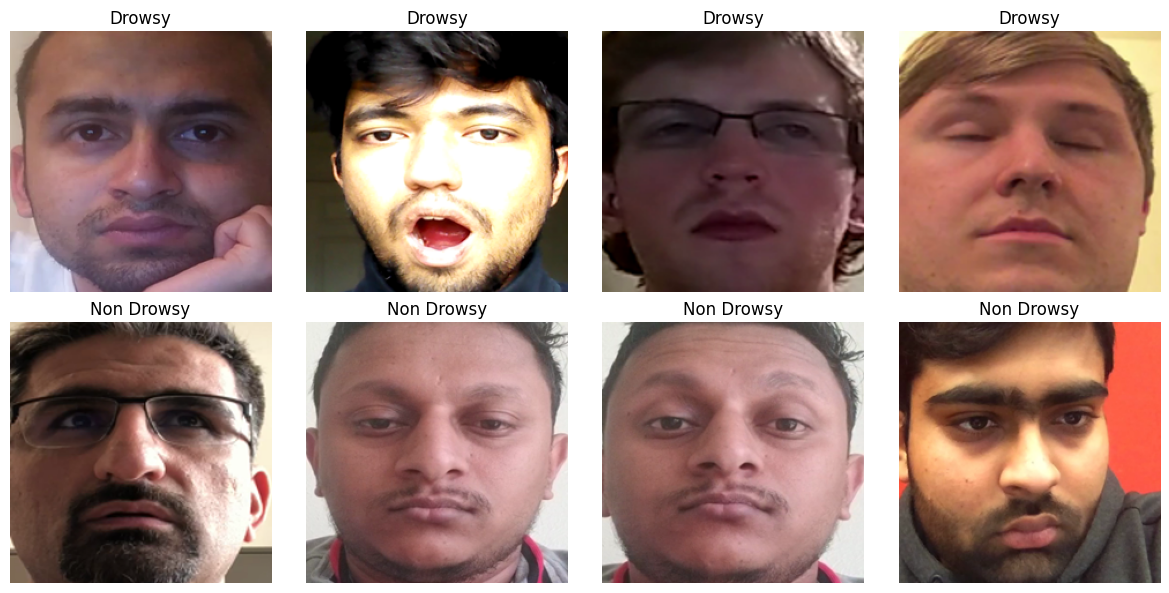

In [61]:
import matplotlib.pyplot as plt
from PIL import Image
import random

classes = ["Drowsy", "Non Drowsy"]

plt.figure(figsize=(12, 6))

plot_index = 1

for class_name in classes:

    folders = [
        p for p in Path(EXTRACT_DIR).rglob("*")
        if p.is_dir() and p.name.lower() == class_name.lower()
    ]

    image_files = []

    for folder in folders:
        image_files.extend([
            f for f in folder.rglob("*")
            if f.suffix.lower() in image_extensions
        ])

    samples = random.sample(
        image_files,
        min(4, len(image_files))
    )

    for image_path in samples:

        image = Image.open(image_path).convert("RGB")

        plt.subplot(2, 4, plot_index)
        plt.imshow(image)
        plt.title(class_name)
        plt.axis("off")

        plot_index += 1

plt.tight_layout()
plt.show()


In [15]:
from pathlib import Path
import os

EXTRACT_DIR = "/content/driver_dataset"

# Find class folders automatically
drowsy_folders = [
    p for p in Path(EXTRACT_DIR).rglob("*")
    if p.is_dir() and p.name.lower() == "drowsy"
]

non_drowsy_folders = [
    p for p in Path(EXTRACT_DIR).rglob("*")
    if p.is_dir() and p.name.lower() == "non drowsy"
]

if not drowsy_folders or not non_drowsy_folders:
    raise ValueError("Could not find both class folders!")

DROWSY_DIR = str(drowsy_folders[0])
NON_DROWSY_DIR = str(non_drowsy_folders[0])

print("Drowsy:", DROWSY_DIR)
print("Non Drowsy:", NON_DROWSY_DIR)


Drowsy: /content/driver_dataset/Driver Drowsiness Dataset (DDD)/Drowsy
Non Drowsy: /content/driver_dataset/Driver Drowsiness Dataset (DDD)/Non Drowsy


In [16]:
import os

DATASET_DIR = os.path.join(
    EXTRACT_DIR,
    "Driver Drowsiness Dataset (DDD)"
)

print("Dataset path:", DATASET_DIR)
print("Folders:", os.listdir(DATASET_DIR))

Dataset path: /content/driver_dataset/Driver Drowsiness Dataset (DDD)
Folders: ['Non Drowsy', 'Drowsy']


In [17]:
import tensorflow as tf

dataset_path = "/content/driver_dataset/Driver Drowsiness Dataset (DDD)"

# 70% Training dataset
train_data = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.30,
    subset="training",
    seed=42,
    image_size=(224, 224),
    batch_size=32,
    label_mode="binary"
)

# Remaining 30% dataset
temp_data = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.30,
    subset="validation",
    seed=42,
    image_size=(224, 224),
    batch_size=32,
    label_mode="binary"
)

# Divide remaining dataset into 15% validation and 15% testing
total_batches = tf.data.experimental.cardinality(temp_data).numpy()

half_batches = total_batches // 2

val_data = temp_data.take(half_batches)

test_data = temp_data.skip(half_batches)

print("Dataset splitting completed!")

Found 41793 files belonging to 2 classes.
Using 29256 files for training.
Found 41793 files belonging to 2 classes.
Using 12537 files for validation.
Dataset splitting completed!


In [18]:
print("Training batches:",
      tf.data.experimental.cardinality(train_data).numpy())

print("Validation batches:",
      tf.data.experimental.cardinality(val_data).numpy())

print("Testing batches:",
      tf.data.experimental.cardinality(test_data).numpy())

Training batches: 915
Validation batches: 196
Testing batches: 196


In [22]:
import tensorflow as tf

train_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/driver_dataset/Driver Drowsiness Dataset (DDD)",
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=(224, 224),
    batch_size=32
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/driver_dataset/Driver Drowsiness Dataset (DDD)",
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=(224, 224),
    batch_size=32)

Found 41793 files belonging to 2 classes.
Using 33435 files for training.
Found 41793 files belonging to 2 classes.
Using 8358 files for validation.


In [23]:
remaining_ds = train_ds

total_batches = tf.data.experimental.cardinality(
    remaining_ds
).numpy()

print("Total batches:", total_batches)

Total batches: 1045


In [24]:
# Count batches in remaining dataset
total_batches = tf.data.experimental.cardinality(
    remaining_ds
).numpy()

print("Remaining batches:", total_batches)

if total_batches < 2:
    raise ValueError("Not enough batches to split validation and testing.")

val_batches = total_batches // 2

val_ds = remaining_ds.take(val_batches)
test_ds = remaining_ds.skip(val_batches)

print("Training, validation and testing datasets prepared.")


Remaining batches: 1045
Training, validation and testing datasets prepared.


In [25]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

print("Dataset pipeline ready!")


Dataset pipeline ready!


In [26]:
model = tf.keras.Sequential([

    tf.keras.layers.Input(shape=(224, 224, 3)),

    tf.keras.layers.Rescaling(1./255),

    tf.keras.layers.Conv2D(32, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2,2),

    tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2,2),

    tf.keras.layers.Conv2D(128, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2,2),

    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dense(128, activation='relu'),

    tf.keras.layers.Dropout(0.5),

    tf.keras.layers.Dense(2, activation='softmax')

])

In [27]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [28]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,018 (429.76 KB)

 Trainable params: 110,018 (429.76 KB)

 Non-trainable params: 0 (0.00 B)

In [30]:
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=5
)

Epoch 1/5
915/915 ━━━━━━━━━━━━━━━━━━━━ 82s 89ms/step - accuracy: 0.9886 - loss: 0.0388 - val_accuracy: 0.9976 - val_loss: 0.0132
Epoch 2/5
915/915 ━━━━━━━━━━━━━━━━━━━━ 87s 94ms/step - accuracy: 0.9931 - loss: 0.0229 - val_accuracy: 0.9976 - val_loss: 0.0089
Epoch 3/5
915/915 ━━━━━━━━━━━━━━━━━━━━ 80s 87ms/step - accuracy: 0.9946 - loss: 0.0183 - val_accuracy: 0.9949 - val_loss: 0.0141
Epoch 4/5
915/915 ━━━━━━━━━━━━━━━━━━━━ 79s 86ms/step - accuracy: 0.9948 - loss: 0.0182 - val_accuracy: 0.9911 - val_loss: 0.0258
Epoch 5/5
915/915 ━━━━━━━━━━━━━━━━━━━━ 81s 89ms/step - accuracy: 0.9957 - loss: 0.0146 - val_accuracy: 0.9888 - val_loss: 0.0308


In [31]:

test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Loss:", test_loss)

print("Test Accuracy:", test_accuracy * 100, "%")


523/523 ━━━━━━━━━━━━━━━━━━━━ 74s 75ms/step - accuracy: 0.9884 - loss: 0.0305
Test Loss: 0.030505839735269547
Test Accuracy: 98.84047508239746 %


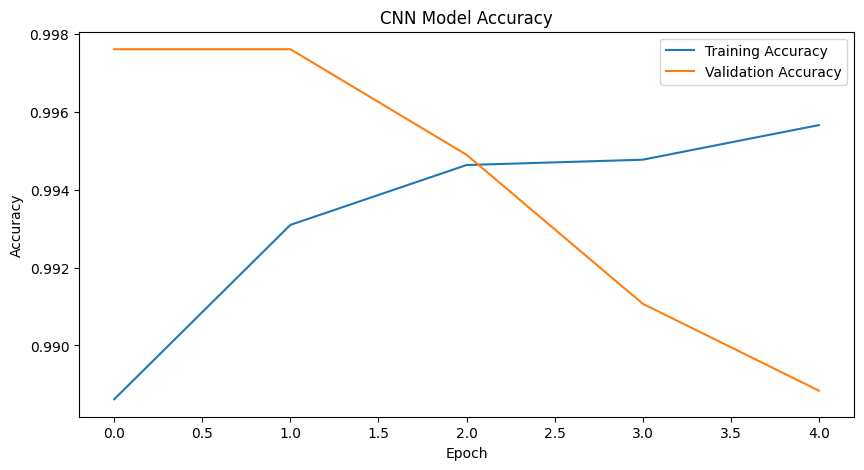

In [32]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")

plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("CNN Model Accuracy")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()

plt.show()


In [33]:
print("Model output shape:", model.output_shape)

Model output shape: (None, 2)


In [34]:
y_true = []
y_pred = []

for images, labels in test_data:

    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy().flatten())

    if predictions.shape[-1] == 2:
        predicted_classes = predictions.argmax(axis=1)
    else:
        predicted_classes = (predictions.reshape(-1) > 0.5).astype(int)

    y_pred.extend(predicted_classes)

In [35]:
print("Actual labels:", len(y_true))
print("Predicted labels:", len(y_pred))

Actual labels: 6265
Predicted labels: 6265


In [36]:
from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    target_names=train_data.class_names
))

              precision    recall  f1-score   support

      Drowsy       1.00      0.98      0.99      3327
  Non Drowsy       0.98      1.00      0.99      2938

    accuracy                           0.99      6265
   macro avg       0.99      0.99      0.99      6265
weighted avg       0.99      0.99      0.99      6265



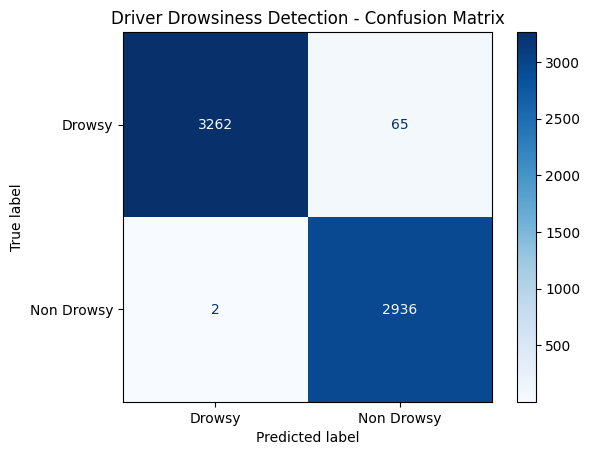

In [37]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=train_data.class_names
)

disp.plot(cmap='Blues')

plt.title("Driver Drowsiness Detection - Confusion Matrix")

plt.show()

In [54]:
import os

image_path = "/content/driver_dataset/Driver Drowsiness Dataset (DDD)/Drowsy/A0999.png"

print(os.path.exists(image_path))

True


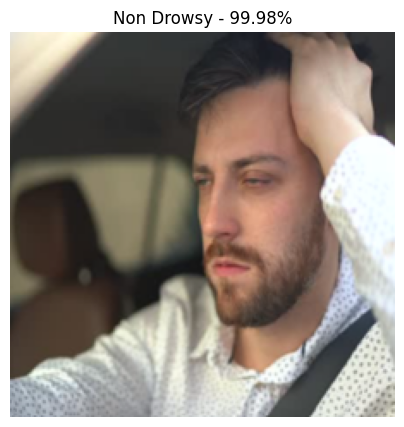

Class names: ['Drowsy', 'Non Drowsy']
Probabilities: [1.5675261e-04 9.9984324e-01]
Prediction: Non Drowsy
Confidence: 0.9998


In [60]:

import numpy as np
import tensorflow as tf
from PIL import Image
import matplotlib.pyplot as plt

# 1. Image path
image_path = "/content/Screenshot 2026-11-19 150807.png"

# 2. Load image
img = Image.open(image_path).convert("RGB")
img = img.resize((224, 224))

# 3. Convert image into array
img_array = np.array(img, dtype=np.float32)
img_array = np.expand_dims(img_array, axis=0)

# 4. Predict
prediction = model.predict(img_array, verbose=0)[0]

# 5. Get predicted class
class_names = train_data.class_names

predicted_class = np.argmax(prediction)
result = class_names[predicted_class]

# 6. Get confidence
confidence = prediction[predicted_class]

# 7. Display image and result
plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.axis("off")
plt.title(f"{result} - {confidence:.2%}")
plt.show()

# 8. Print output
print("Class names:", class_names)
print("Probabilities:", prediction)
print("Prediction:", result)
print("Confidence:", round(float(confidence), 4))


In [56]:
import os

MODEL_PATH = os.path.join(
    PROJECT_DIR,
    "drowsiness_model.keras"
)

model.save(MODEL_PATH)

print("Model saved:", MODEL_PATH)

Model saved: /content/drive/MyDrive/Driver_Drowsiness_Project/drowsiness_model.keras


In [41]:
image_path = "/content/driver_dataset/Driver Drowsiness Dataset (DDD)/Non Drowsy/h0266.png"

from PIL import Image
import numpy as np

img = Image.open(image_path).convert("RGB")
img = img.resize((224, 224))

img_array = np.array(img)
img_array = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_array)

print("Raw prediction:", prediction)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
Raw prediction: [[6.5426830e-06 9.9999344e-01]]


In [42]:
print(train_data.class_names)

['Drowsy', 'Non Drowsy']


In [43]:
if prediction[0][0] >= 0.5:
    print("Drowsy")
else:
    print("Non Drowsy")

Non Drowsy
